# Análisis del mercado Airbnb en las principales ciudades turísticas de España

## Introducción

El turismo en España ha experimentado un crecimiento sostenido en las últimas décadas, 
consolidando al país como uno de los destinos más visitados del mundo. En paralelo, 
plataformas como Airbnb han transformado el mercado del alquiler, generando un debate 
creciente sobre su impacto en el acceso a la vivienda residencial.

## Objetivos

El objetivo de este análisis es explorar el mercado de alojamiento turístico en las 
cuatro principales ciudades turísticas de España (Barcelona, Madrid, Valencia y Sevilla), 
e investigar si existe una relación entre la concentración de pisos turísticos y los 
precios del alquiler residencial.

## Hipótesis

A mayor concentración de alojamientos turísticos en una ciudad, mayor es el precio 
del alquiler residencial para sus habitantes.

In [96]:
## 1. Importación de librerías

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style="whitegrid")

## 2. Carga de datos

Para este análisis utilizo dos fuentes de datos distintas:
- Datos de Airbnb extraídos de Inside Airbnb para las ciudades de Barcelona, Madrid, Valencia y Sevilla.
- Datos de precios de alquiler residencial por municipio (Índice VIA, Ministerio de Vivienda, 2026).

Cargo cada ciudad por separado y les añado una columna con el nombre de la ciudad antes de unirlas.

In [98]:
# Cargo los listings de cada ciudad por separado y añado la columna ciudad
bcn = pd.read_csv('../data/raw/listings_Barcelona.csv')
bcn['ciudad'] = 'Barcelona'

mad = pd.read_csv('../data/raw/listings_Madrid.csv')
mad['ciudad'] = 'Madrid'

val = pd.read_csv('../data/raw/listings_Valencia.csv')
val['ciudad'] = 'Valencia'

sev = pd.read_csv('../data/raw/listings_Sevilla.csv')
sev['ciudad'] = 'Sevilla'

# Uno los cuatro datasets en uno solo
df_airbnb = pd.concat([bcn, mad, val, sev], ignore_index=True)

print(f"Dataset total: {df_airbnb.shape[0]} filas y {df_airbnb.shape[1]} columnas")

Dataset total: 54688 filas y 20 columnas


In [99]:
# Cargo el segundo dataset, que es el de precios de alquiler residencial por municipio
df_alquiler = pd.read_csv('../data/raw/municipal-dataset.csv')

print(f"Dataset alquiler: {df_alquiler.shape[0]} filas y {df_alquiler.shape[1]} columnas")
df_alquiler.head()

Dataset alquiler: 8110 filas y 14 columnas


,municipio,provincia,codigo_ine,lat,lon,poblacion_2025,poblacion_1996,var_1996_2025_pct,var_10a_pct,alquiler_eur_m2,alquiler_p25,alquiler_p75,alquiler_80m2_mes,anuncios
0,Madrid,Madrid,28079,40.416782,-3.703507,3506730,2866850.0,22.3,10.8,19.27,11.00,28.38,1541.0,40.0
1,Barcelona,Barcelona,8019,41.382580,2.177073,1731649,1508805.0,14.8,7.6,20.00,16.00,27.86,1600.0,31.0
2,València,Valencia,46250,39.469707,-0.376335,840792,746683.0,12.6,6.4,15.56,11.33,19.86,1245.0,49.0
3,Zaragoza,Zaragoza,50297,41.652134,-0.880943,693091,601674.0,15.2,4.8,12.50,9.31,16.27,1000.0,53.0
4,Sevilla,Sevilla,41091,37.388630,-5.995340,689423,697487.0,-1.2,-0.2,11.96,8.78,15.91,957.0,52.0


## 3. Exploración inicial de los datos

Antes de limpiar nada, exploro los datasets para entender su estructura, 
qué columnas tienen, qué tipos de datos hay y si existen valores nulos.

In [100]:
# Primero miro la estructura general del dataset de Airbnb
print("=== AIRBNB ===")
print(f"Dimensiones: {df_airbnb.shape}")
print("\nTipos de datos:")
print(df_airbnb.dtypes)
print("\nPrimeras filas:")
df_airbnb.head()

=== AIRBNB ===
Dimensiones: (54688, 20)

Tipos de datos:
id                                  int64
name                                  str
host_id                             int64
host_profile_id                     int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                               str
ciudad                                str
dtype: object

Primeras filas:


,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,ciudad
0,18674,Huge flat for 8 people close to Sagrada Familia,71615,1462508358342835057,Maria Y Mireia Y Ana Barcelona4Seasons,Eixample,la Sagrada Família,41.40556,2.17262,Entire home/apt,274.0,1.0,60,2026-07-20,0.37,21,162,8,Spain - National registration number<br />ESFC...,Barcelona
1,23197,CCIB Forum • Spacious 3BR • Large Balcony,90417,1462509351463595774,Marnie,Sant Martí,el Besòs i el Maresme,41.41243,2.21975,Entire home/apt,408.0,3.0,102,2026-09-07,0.54,1,128,11,Spain - National registration number<br />ESFC...,Barcelona
2,34981,VIDRE HOME PLAZA REAL on LAS RAMBLAS,73163,1462508447204147103,Andres,Ciutat Vella,el Barri Gòtic,41.37978,2.17623,Entire home/apt,546.0,1.0,314,2026-09-13,1.62,2,316,43,Spain - National registration number<br />ESFC...,Barcelona
3,36763,In front of the beach,158596,1462511238526662756,Ester,Ciutat Vella,la Barceloneta,41.38043,2.19094,Private room,44.0,31.0,108,2023-12-13,0.59,1,77,0,NaN,Barcelona
4,40983,Architect's Loft near Gaudí & Passeig de Gràcia,177617,1462511822388459344,Joaquin Fernandez,Eixample,la Dreta de l'Eixample,41.39631,2.16832,Entire home/apt,187.0,1.0,464,2026-09-13,2.50,5,283,62,Barcelona - Regional registration number<br />...,Barcelona


In [101]:
# Reviso cuántos valores nulos tiene cada columna
print("Valores nulos en df_airbnb:")
print(df_airbnb.isnull().sum())

Valores nulos en df_airbnb:
id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                              8373
minimum_nights                     6571
number_of_reviews                     0
last_review                        8613
reviews_per_month                  8613
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                           21278
ciudad                                0
dtype: int64


Al revisar los nulos me ha llamado la atención que casi el 40% de los listings 
no tienen licencia turística registrada. Esto no significa necesariamente que 
operen ilegalmente, pero sí refleja una realidad del sector: la regulación 
de los alojamientos turísticos todavía es muy irregular en España y varía 
mucho según la ciudad. He decidido mantener esta columna en el análisis 
precisamente porque su ausencia también aporta información relevante.

En cuanto al precio, he optado por eliminar los registros sin valor ya que 
es la variable central de todo el análisis y no tiene sentido imputar un precio.

## 4. Limpieza de datos

Tras explorar el dataset, identifico los siguientes problemas a resolver:
- Eliminar filas sin precio, ya que son esenciales para el análisis.
- La columna license tiene muchos nulos pero la mantengo porque su ausencia también es informativa.
- Convertir last_review a formato fecha.
- Los nulos de reviews_per_month los relleno con 0, ya que indican que el listing no tiene reviews.

In [102]:
# Elimino filas sin precio porque son esenciales para el análisis
df_airbnb = df_airbnb.dropna(subset=['price'])
print(f"Filas después de eliminar nulos en price: {len(df_airbnb)}")

# Relleno nulos de reviews_per_month con 0
df_airbnb['reviews_per_month'] = df_airbnb['reviews_per_month'].fillna(0)

# Convierto last_review a formato fecha
df_airbnb['last_review'] = pd.to_datetime(df_airbnb['last_review'], errors='coerce')

print("Limpieza completada")

Filas después de eliminar nulos en price: 46315
Limpieza completada


In [103]:
# Reviso si hay precios extremos o incorrectos
print("Estadísticas de precio:")
print(df_airbnb['price'].describe())

Estadísticas de precio:
count    46315.000000
mean       213.427291
std        431.516486
min          9.000000
25%        100.000000
50%        155.000000
75%        234.000000
max      36883.000000
Name: price, dtype: float64


In [104]:
# Reviso cuántos listings tienen precios muy altos (outliers)
print(f"Listings con precio > 1000€: {len(df_airbnb[df_airbnb['price'] > 1000])}")
print(f"Listings con precio > 2000€: {len(df_airbnb[df_airbnb['price'] > 2000])}")

# Elimino outliers extremos de precio (más de 1000€ por noche)
df_airbnb = df_airbnb[df_airbnb['price'] <= 1000]
print(f"\nFilas después de eliminar outliers de precio: {len(df_airbnb)}")

Listings con precio > 1000€: 571
Listings con precio > 2000€: 233

Filas después de eliminar outliers de precio: 45744


He decidido eliminar los listings con precio superior a 1000€ por noche ya que representan menos del 1.5% del total y corresponden a propiedades de lujo que no son representativas del mercado turístico general. Mantenerlos distorsionaría las medias y las visualizaciones.

In [105]:
# Reviso minimum_nights
print("Estadísticas de minimum_nights:")
print(df_airbnb['minimum_nights'].describe())
print(f"\nListings con minimum_nights > 30: {len(df_airbnb[df_airbnb['minimum_nights'] > 30])}")

# Elimino registros con minimum_nights nulo
df_airbnb = df_airbnb.dropna(subset=['minimum_nights'])
print(f"Filas después de eliminar nulos en minimum_nights: {len(df_airbnb)}")

Estadísticas de minimum_nights:
count    39696.000000
mean         8.360187
std         15.668166
min          1.000000
25%          1.000000
50%          2.000000
75%          7.000000
max        365.000000
Name: minimum_nights, dtype: float64

Listings con minimum_nights > 30: 5404
Filas después de eliminar nulos en minimum_nights: 39696


He detectado que algunos listings exigen más de 30 noches mínimas, lo que indica que no son alojamientos turísticos sino alquileres de media o larga duración. 
Los elimino del análisis ya que el objetivo es estudiar el mercado turístico, 
no el residencial.

In [106]:
# Elimino listings con estancia mínima superior a 30 noches (no son turísticos)
df_airbnb = df_airbnb[df_airbnb['minimum_nights'] <= 30]
print(f"Filas después de eliminar estancias largas: {len(df_airbnb)}")

Filas después de eliminar estancias largas: 34292


Antes de hacer el merge, realizo algunos pasos adicionales de limpieza y 
transformación: elimino duplicados, verifico los tipos de alojamiento, 
creo variables nuevas que serán útiles para el análisis y reseteo el índice.

In [107]:
# Compruebo y elimino duplicados por id de listing
print(f"Duplicados encontrados: {df_airbnb.duplicated(subset='id').sum()}")
df_airbnb = df_airbnb.drop_duplicates(subset='id')
print(f"Filas tras eliminar duplicados: {len(df_airbnb)}")

Duplicados encontrados: 0
Filas tras eliminar duplicados: 34292


In [108]:
# Reviso los tipos de alojamiento disponibles
print("Tipos de alojamiento:")
print(df_airbnb['room_type'].value_counts())

Tipos de alojamiento:
room_type
Entire home/apt    25775
Private room        8117
Shared room          271
Hotel room           129
Name: count, dtype: int64


El 75% de los alojamientos son pisos enteros, lo cual es especialmente relevante para nuestra hipótesis: un piso entero en Airbnb es una vivienda que ha salido del mercado residencial. Cuantos más pisos enteros haya en una ciudad, menos  oferta de alquiler residencial existe para sus habitantes.

Uno de los aspectos más interesantes del debate sobre Airbnb es la diferencia  entre un particular que alquila su propia vivienda ocasionalmente y un inversor que gestiona múltiples propiedades de forma profesional. Para distinguirlos, creo una variable nueva basada en el número de listings por host: si tiene más de uno, lo clasifico como host profesional. También extraigo el año de la última review para poder analizar qué listings han tenido actividad reciente.

In [109]:
# Creo una columna para identificar hosts profesionales (más de 1 listing)
df_airbnb['host_profesional'] = df_airbnb['calculated_host_listings_count'].apply(
    lambda x: 'Profesional' if x > 1 else 'Particular'
)

# Extraigo el año de la última review para analizar actividad reciente
df_airbnb['año_ultima_review'] = df_airbnb['last_review'].dt.year

# Reseteo el índice después de todos los filtros
df_airbnb = df_airbnb.reset_index(drop=True)

print("Nuevas columnas creadas correctamente")
print(f"\nDistribución host profesional vs particular:")
print(df_airbnb['host_profesional'].value_counts())

Nuevas columnas creadas correctamente

Distribución host profesional vs particular:
host_profesional
Profesional    25684
Particular      8608
Name: count, dtype: int64


Tres de cada cuatro listings en estas ciudades pertenecen a hosts con más de una propiedad. Esto confirma que Airbnb en las grandes ciudades españolas no es principalmente un fenómeno de economía colaborativa entre particulares, sino un negocio profesionalizado donde inversores gestionan múltiples propiedades simultáneamente.

## 5. Merge de los datasets

Una vez limpio el dataset de Airbnb, lo combino con los datos de precios de alquiler residencial por municipio. El cruce se hace por ciudad, lo que me permite enriquecer cada listing con información sobre el precio del alquiler residencial en esa misma ciudad.

Antes del merge, homogeneizo el nombre de Valencia ya que en el dataset de alquiler aparece como "València".

In [110]:
# Homogeneizo el nombre de Valencia en el dataset de alquiler
df_alquiler['municipio'] = df_alquiler['municipio'].replace('València', 'Valencia')

# Filtro solo las 4 ciudades del análisis
ciudades = ['Barcelona', 'Madrid', 'Valencia', 'Sevilla']
df_alquiler_filtrado = df_alquiler[df_alquiler['municipio'].isin(ciudades)]

print("Datos de alquiler para las 4 ciudades:")
print(df_alquiler_filtrado[['municipio', 'alquiler_eur_m2', 'alquiler_80m2_mes']])

Datos de alquiler para las 4 ciudades:
   municipio  alquiler_eur_m2  alquiler_80m2_mes
0     Madrid            19.27             1541.0
1  Barcelona            20.00             1600.0
2   Valencia            15.56             1245.0
4    Sevilla            11.96              957.0


In [111]:
# Hago el merge uniendo por ciudad
df_final = df_airbnb.merge(
    df_alquiler_filtrado[['municipio', 'alquiler_eur_m2', 'alquiler_p25', 'alquiler_p75', 'alquiler_80m2_mes', 'poblacion_2025']],
    left_on='ciudad',
    right_on='municipio',
    how='left'
)

# Elimino la columna municipio que queda duplicada tras el merge
df_final = df_final.drop(columns='municipio')

print(f"Dataset final: {df_final.shape[0]} filas y {df_final.shape[1]} columnas")
print(f"\nColumnas: {list(df_final.columns)}")

Dataset final: 34292 filas y 27 columnas

Columnas: ['id', 'name', 'host_id', 'host_profile_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'license', 'ciudad', 'host_profesional', 'año_ultima_review', 'alquiler_eur_m2', 'alquiler_p25', 'alquiler_p75', 'alquiler_80m2_mes', 'poblacion_2025']


In [112]:
# Guardo el dataset final limpio en la carpeta processed
df_final.to_csv('../data/processed/airbnb_limpio.csv', index=False)
print("Dataset guardado correctamente en data/processed/airbnb_limpio.csv")

Dataset guardado correctamente en data/processed/airbnb_limpio.csv


## 6. Análisis descriptivo

Con el dataset final limpio, analizo las principales características del mercado Airbnb en las cuatro ciudades. El objetivo es entender la distribución de precios, el tipo de alojamiento predominante y las diferencias entre ciudades.

In [113]:
# Estadísticas descriptivas generales del dataset final
df_final[['price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'calculated_host_listings_count']].describe().round(2)

,price,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
count,34292.00,34292.00,34292.00,34292.00,34292.00
mean,194.35,3.91,90.52,203.95,34.35
std,135.74,6.75,136.57,115.12,84.14
min,9.00,1.00,0.00,0.00,1.00
25%,108.00,1.00,5.00,94.00,1.00
50%,162.00,2.00,38.00,229.00,5.00
75%,241.00,3.00,117.00,312.00,22.00
max,1000.00,30.00,3111.00,365.00,519.00


Las estadísticas descriptivas revelan datos interesantes. El precio medio por noche es de 194€, aunque la mediana (162€) indica que hay listings muy caros que elevan la media. 

Llama especialmente la atención que algunos hosts gestionan hasta 519 propiedades simultáneamente, confirmando la presencia de grandes operadores profesionales en el mercado.

In [114]:
# Precio medio por ciudad
print("Precio medio por noche por ciudad:")
print(df_final.groupby('ciudad')['price'].mean().round(2).sort_values(ascending=False))

Precio medio por noche por ciudad:
ciudad
Barcelona    267.97
Sevilla      185.43
Madrid       184.50
Valencia     149.61
Name: price, dtype: float64


Barcelona destaca como la ciudad con el precio medio más alto (267€ por noche), muy por encima del resto. Sorprende que Sevilla supere a Madrid en precio medio, aunque probablemente se deba a una mayor proporción de alojamientos de tipo 
piso entero. Valencia es la más asequible de las cuatro.

In [115]:
# Distribución de tipo de alojamiento por ciudad
room_ciudad = df_final.groupby(['ciudad', 'room_type']).size().unstack(fill_value=0)
room_ciudad_pct = room_ciudad.div(room_ciudad.sum(axis=1), axis=0).round(3) * 100
print("Porcentaje de cada tipo de alojamiento por ciudad:")
print(room_ciudad_pct)

Porcentaje de cada tipo de alojamiento por ciudad:
room_type  Entire home/apt  Hotel room  Private room  Shared room
ciudad                                                           
Barcelona             76.9         1.1          20.5          1.5
Madrid                70.4         0.2          28.6          0.8
Sevilla               85.0         0.3          14.4          0.4
Valencia              76.0         0.2          23.5          0.3


Sevilla tiene el mayor porcentaje de pisos enteros (85%), lo que explica que su precio medio supere al de Madrid. En todas las ciudades el piso entero es el tipo dominante, lo que tiene implicaciones directas sobre el mercado residencial: estos alojamientos son viviendas completas que han dejado de estar disponibles para los residentes locales. Madrid es la ciudad con mayor proporción de habitaciones privadas (28.6%), lo que sugiere un perfil algo más diversificado.

In [116]:
# Distribución de host profesional vs particular por ciudad
host_ciudad = df_final.groupby(['ciudad', 'host_profesional']).size().unstack(fill_value=0)
host_ciudad_pct = host_ciudad.div(host_ciudad.sum(axis=1), axis=0).round(3) * 100
print("Porcentaje de host profesional vs particular por ciudad:")
print(host_ciudad_pct)

Porcentaje de host profesional vs particular por ciudad:
host_profesional  Particular  Profesional
ciudad                                   
Barcelona               17.0         83.0
Madrid                  25.1         74.9
Sevilla                 28.0         72.0
Valencia                31.0         69.0


Barcelona lidera la profesionalización del mercado Airbnb: 8 de cada 10 listings pertenecen a hosts con más de una propiedad. Esto refuerza la idea de que en Barcelona Airbnb ha dejado de ser una plataforma de economía colaborativa para convertirse principalmente en un negocio de inversión inmobiliaria. Valencia y Sevilla muestran un mercado algo más equilibrado, aunque los profesionales siguen siendo mayoría en todas las ciudades analizadas.

In [117]:
# Comparativa precio Airbnb vs alquiler residencial por ciudad
comparativa = df_final.groupby('ciudad').agg(
    precio_airbnb_noche=('price', 'mean'),
    alquiler_residencial_m2=('alquiler_eur_m2', 'mean'),
    alquiler_80m2_mes=('alquiler_80m2_mes', 'mean')
).round(2)

print("Comparativa Airbnb vs alquiler residencial:")
print(comparativa)

Comparativa Airbnb vs alquiler residencial:
           precio_airbnb_noche  alquiler_residencial_m2  alquiler_80m2_mes
ciudad                                                                    
Barcelona               267.97                    20.00             1600.0
Madrid                  184.50                    19.27             1541.0
Sevilla                 185.43                    11.96              957.0
Valencia                149.61                    15.56             1245.0


La comparativa entre precios de Airbnb y alquiler residencial muestra una correlación clara: las ciudades con precios de Airbnb más altos también tienen los alquileres residenciales más caros. Barcelona encabeza ambos rankings con 268€ de media por noche en Airbnb y 1.600€ al mes por un piso de 80m². 

El caso más llamativo es Sevilla: a pesar de tener precios de Airbnb similares a Madrid (185€ vs 184€), su alquiler residencial es significativamente más bajo (957€ vs 1.541€), lo que podría indicar que la presión turística en Sevilla aún no ha impactado tanto en el mercado residencial como en Madrid o Barcelona.

## 7. Visualizaciones

A continuación presento una serie de gráficos que permiten visualizar los principales hallazgos del análisis descriptivo.

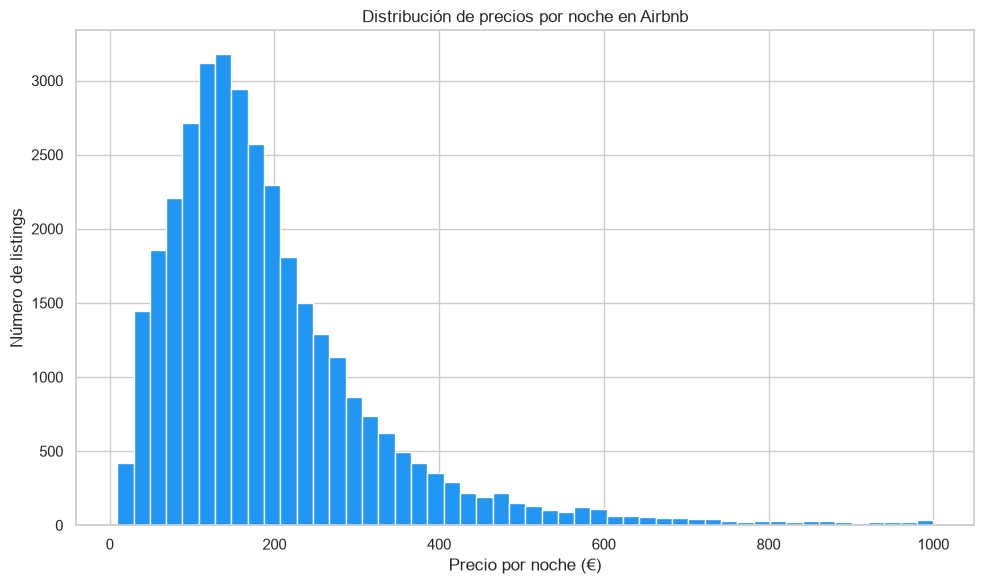

In [118]:
# Distribución general de precios
plt.figure(figsize=(10, 6))
plt.hist(df_final['price'], bins=50, color='#2196F3', edgecolor='white')
plt.title('Distribución de precios por noche en Airbnb')
plt.xlabel('Precio por noche (€)')
plt.ylabel('Número de listings')
plt.tight_layout()
plt.savefig('../reports/distribucion_precios.png', dpi=150)
plt.show()

La distribución de precios muestra una clara asimetría hacia la derecha: la mayoría de los alojamientos se sitúan entre 100€ y 200€ por noche, pero existe una cola de listings con precios muy elevados que elevan la media 
por encima de la mediana, tiene sentido por el tipo de mercado (alojamiento turístico).

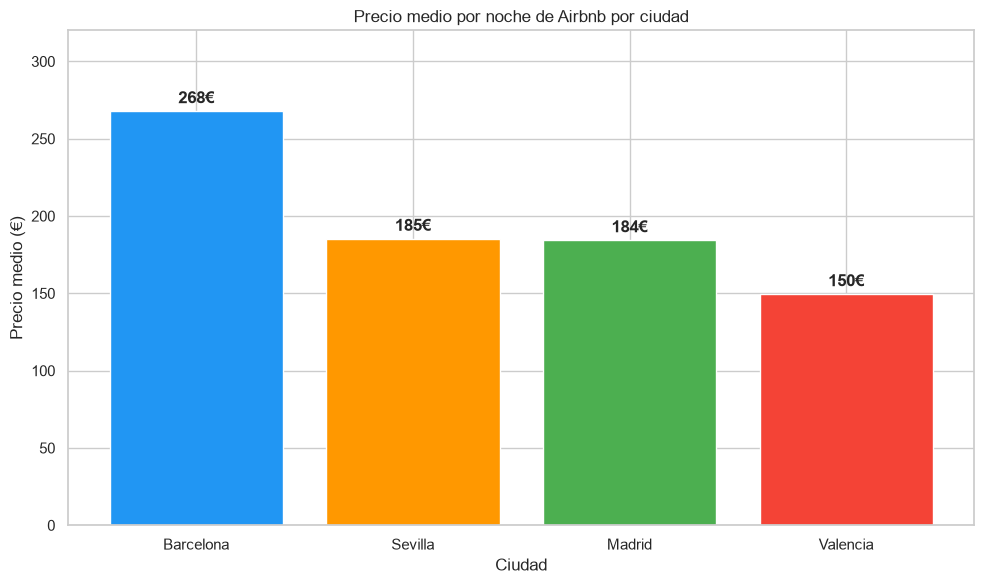

In [119]:
# Precio medio por noche por ciudad
precio_ciudad = df_final.groupby('ciudad')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(precio_ciudad.index, precio_ciudad.values, color=['#2196F3', '#FF9800', '#4CAF50', '#F44336'])
plt.title('Precio medio por noche de Airbnb por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Precio medio (€)')
plt.ylim(0, 320)
for i, v in enumerate(precio_ciudad.values):
    plt.text(i, v + 5, f'{v:.0f}€', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/precio_medio_ciudad.png', dpi=150)
plt.show()

Barcelona destaca claramente como la ciudad más cara, con un precio medio de 268€ por noche, casi un 80% más que Valencia (150€). Sevilla y Madrid están muy igualadas en torno a los 184-185€, lo que sugiere un mercado turístico de similar intensidad en ambas ciudades a pesar de sus diferencias en tamaño.

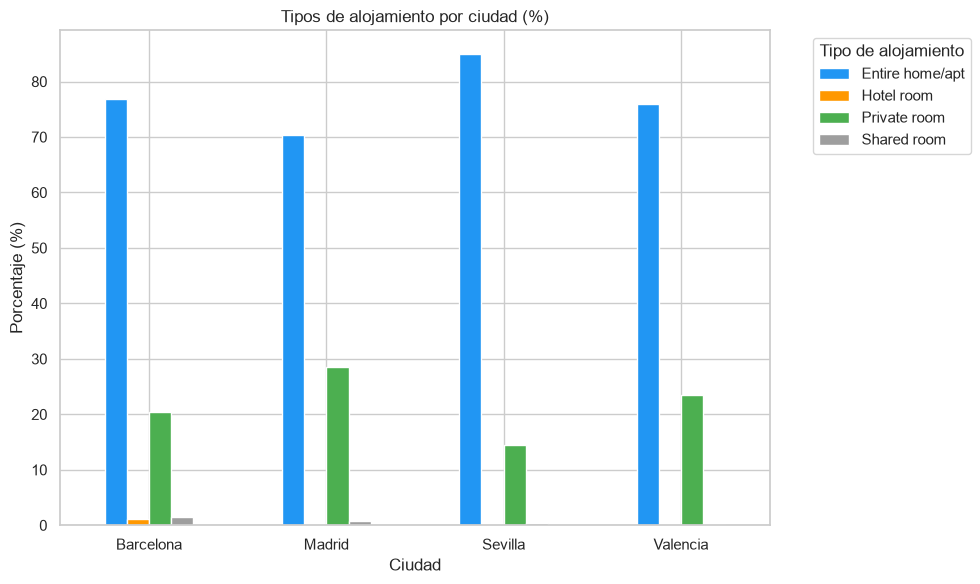

In [120]:
# Tipos de alojamiento por ciudad
room_ciudad = df_final.groupby(['ciudad', 'room_type']).size().unstack(fill_value=0)
room_ciudad_pct = room_ciudad.div(room_ciudad.sum(axis=1), axis=0) * 100

room_ciudad_pct.plot(kind='bar', figsize=(10, 6), 
                     color=['#2196F3', '#FF9800', '#4CAF50', '#9E9E9E'])
plt.title('Tipos de alojamiento por ciudad (%)')
plt.xlabel('Ciudad')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.legend(title='Tipo de alojamiento', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.savefig('../reports/tipos_alojamiento_ciudad.png', dpi=150)
plt.show()

En todas las ciudades el piso entero (Entire home/apt) es el tipo de alojamiento dominante, siendo Sevilla la que presenta mayor proporción (85%). Madrid destaca por tener la mayor oferta de habitaciones privadas (29%), lo que indica un perfil de viajero algo diferente al del resto de ciudades.

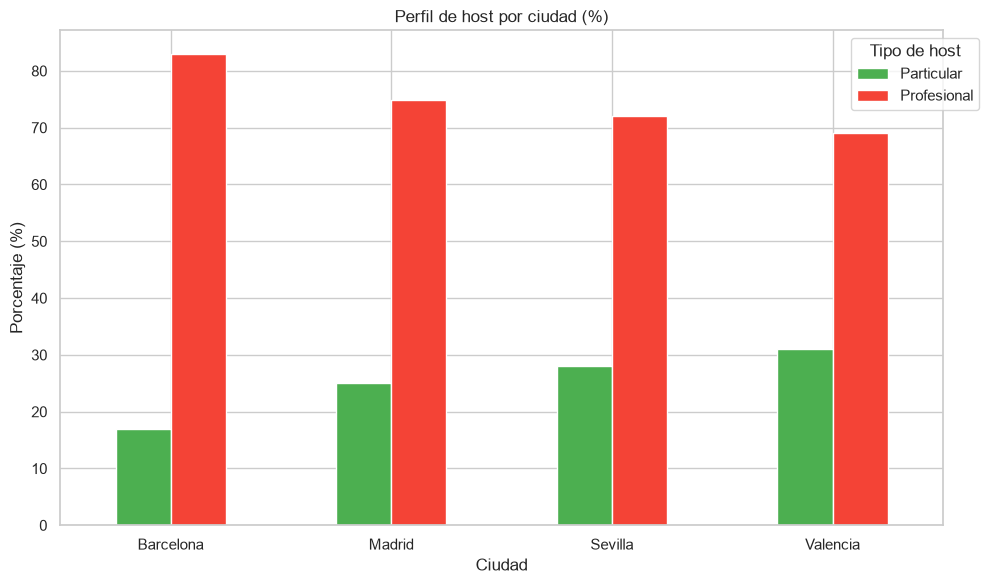

In [121]:
# Host profesional vs particular por ciudad
host_ciudad = df_final.groupby(['ciudad', 'host_profesional']).size().unstack(fill_value=0)
host_ciudad_pct = host_ciudad.div(host_ciudad.sum(axis=1), axis=0) * 100

host_ciudad_pct.plot(kind='bar', figsize=(10, 6), color=['#4CAF50', '#F44336'])
plt.title('Perfil de host por ciudad (%)')
plt.xlabel('Ciudad')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.legend(title='Tipo de host', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.savefig('../reports/host_profesional_ciudad.png', dpi=150)
plt.show()

Barcelona es la ciudad más profesionalizada: el 83% de sus listings pertenecen a hosts con más de una propiedad, frente al 69% de Valencia que es la más equilibrada. En ninguna ciudad los particulares superan el 31%, lo que confirma que Airbnb en las grandes ciudades españolas ha dejado de ser una plataforma entre particulares para convertirse en un mercado dominado por inversores profesionales.

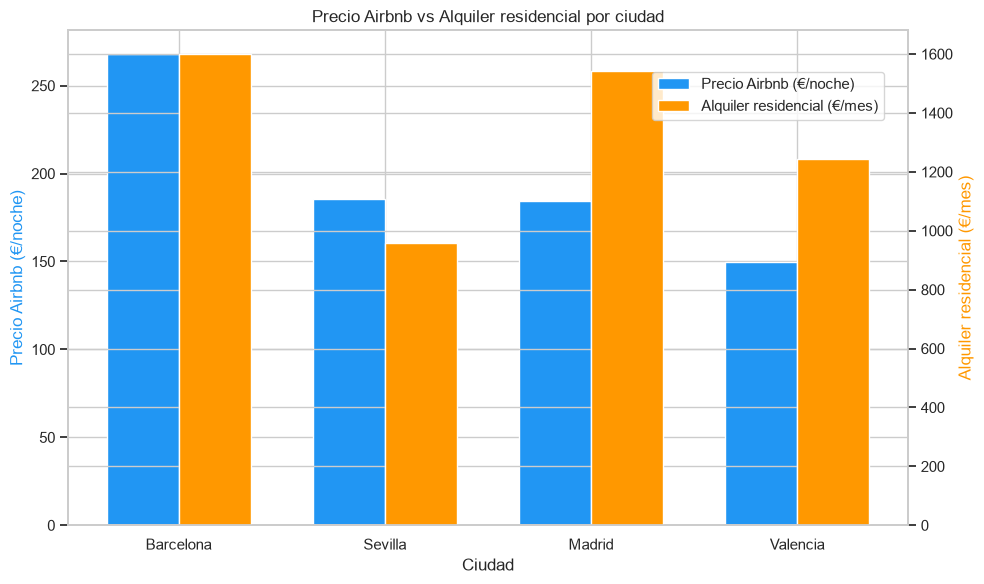

In [122]:
# Comparativa precio Airbnb vs alquiler residencial
comparativa = df_final.groupby('ciudad').agg(
    precio_airbnb=('price', 'mean'),
    alquiler_mes=('alquiler_80m2_mes', 'mean')
).reset_index().sort_values('precio_airbnb', ascending=False)

x = range(len(comparativa))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

bars1 = ax1.bar([i - width/2 for i in x], comparativa['precio_airbnb'], 
                width, label='Precio Airbnb (€/noche)', color='#2196F3')
ax1.set_xlabel('Ciudad')
ax1.set_ylabel('Precio Airbnb (€/noche)', color='#2196F3')
ax1.set_xticks(x)
ax1.set_xticklabels(comparativa['ciudad'])

ax2 = ax1.twinx()
bars2 = ax2.bar([i + width/2 for i in x], comparativa['alquiler_mes'], 
                width, label='Alquiler residencial (€/mes)', color='#FF9800')
ax2.set_ylabel('Alquiler residencial (€/mes)', color='#FF9800')

plt.title('Precio Airbnb vs Alquiler residencial por ciudad')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig('../reports/airbnb_vs_alquiler.png', dpi=150)
plt.show()

Este gráfico muestra la relación entre el precio medio de Airbnb y el alquiler residencial en cada ciudad. Barcelona y Madrid presentan los alquileres residenciales más elevados y también los precios de Airbnb más altos, lo que apoya la hipótesis inicial. El caso más llamativo es Madrid: aunque su precio de Airbnb es similar al de Sevilla, su alquiler residencial es significativamente más alto (1.541€ vs 957€), lo que podría indicar que otros factores además del turismo presionan el mercado de vivienda en la capital.

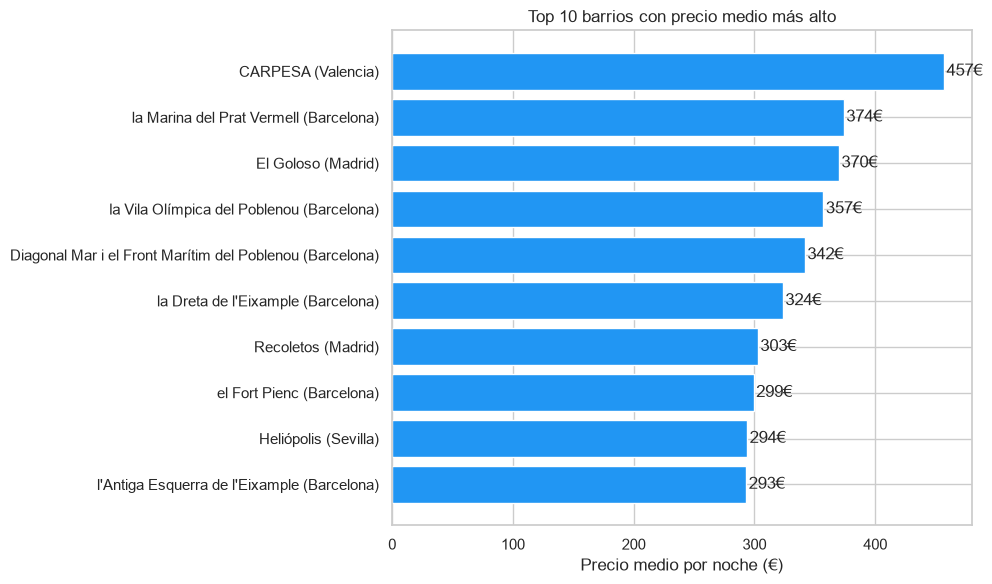

In [123]:
# Top 10 barrios con precio medio más alto
top_barrios = df_final.groupby(['neighbourhood', 'ciudad'])['price'].mean().sort_values(ascending=False).head(10).reset_index()
top_barrios['barrio_ciudad'] = top_barrios['neighbourhood'] + ' (' + top_barrios['ciudad'] + ')'

plt.figure(figsize=(10, 6))
plt.barh(top_barrios['barrio_ciudad'], top_barrios['price'], color='#2196F3')
plt.xlabel('Precio medio por noche (€)')
plt.title('Top 10 barrios con precio medio más alto')
plt.gca().invert_yaxis()
for i, v in enumerate(top_barrios['price']):
    plt.text(v + 2, i, f'{v:.0f}€', va='center')
plt.tight_layout()
plt.savefig('../reports/top10_barrios_caros.png', dpi=150)
plt.show()

El gráfico confirma que Barcelona concentra la mayoría de los barrios más caros, con zonas como la Vila Olímpica o el Front Marítim superando los 340€ de media por noche. Destaca también CARPESA en Valencia, que aparece en primera posición con 457€, aunque hay que tomar este dato con cautela porque probablemente tiene pocas listings que elevan la media. En cualquier caso, queda claro que la presión turística no se distribuye igual por todas las ciudades ni por todos los barrios.

Antes de cerrar el análisis visual, quiero ver cómo se distribuyen los precios dentro de cada ciudad, no solo el promedio. El boxplot me permite identificar la mediana, los cuartiles y los valores atípicos de cada mercado.

C:\Users\mmontllo\AppData\Local\Temp\ipykernel_110132\3946909123.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='ciudad', y='price',


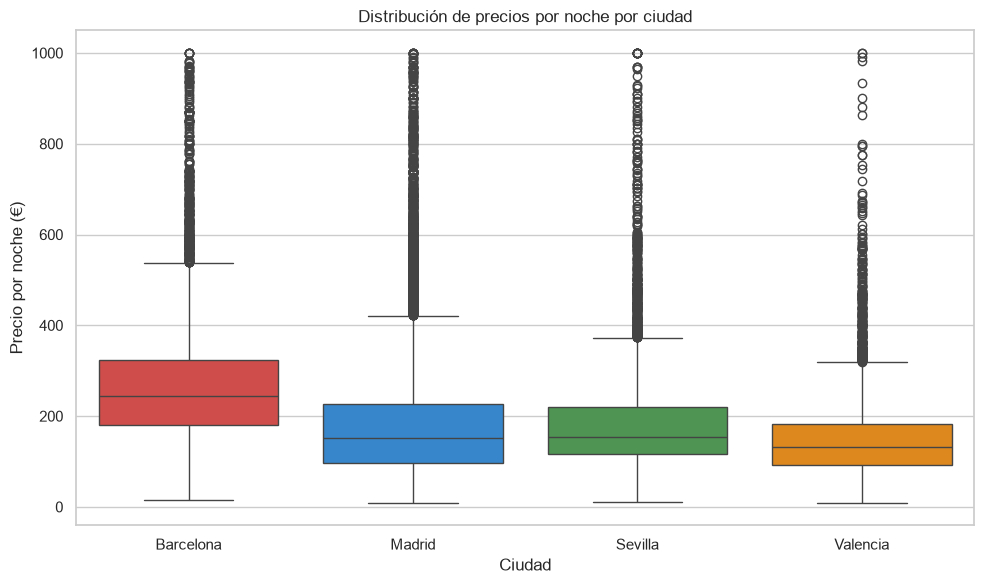

In [124]:
# Boxplot de precios por noche por ciudad
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_final, x='ciudad', y='price',
            order=['Barcelona', 'Madrid', 'Sevilla', 'Valencia'],
            palette=['#E53935', '#1E88E5', '#43A047', '#FB8C00'])
plt.title('Distribución de precios por noche por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Precio por noche (€)')
plt.tight_layout()
plt.savefig('../reports/boxplot_precios_ciudad.png', dpi=150)
plt.show()

El boxplot confirma lo que ya intuíamos: Barcelona es la ciudad con los precios de Airbnb más elevados y con mayor variabilidad, lo que refleja un mercado turístico muy fragmentado entre zonas de lujo y zonas más asequibles. Madrid y Sevilla tienen distribuciones más compactas, y Valencia es la más económica de las cuatro. En todas las ciudades se observan valores atípicos por encima de los 500€, que corresponden a propiedades de lujo o alojamientos muy grandes.

## 8. Análisis estadístico

Para cerrar el análisis, calculo las estadísticas descriptivas principales por ciudad usando pandas y numpy: media, mediana y desviación estándar del precio por noche. Esto me permite comparar no solo el precio medio sino también la variabilidad de cada mercado. Además, calculo la correlación entre el precio medio de Airbnb y el precio del alquiler residencial para ver si existe relación entre ambas variables.

In [125]:
import numpy as np

# Estadísticas descriptivas por ciudad
stats_ciudad = df_final.groupby('ciudad')['price'].agg(
    media='mean',
    mediana='median',
    desv_tipica='std',
    minimo='min',
    maximo='max'
).round(2)
print("Estadísticas de precio por noche por ciudad:")
print(stats_ciudad)

# Correlación entre precio Airbnb y alquiler residencial
correlacion = df_final.groupby('ciudad')[['price', 'alquiler_eur_m2']].mean()
r = correlacion['price'].corr(correlacion['alquiler_eur_m2'])
print(f"\nCorrelación de Pearson (precio Airbnb vs alquiler residencial): r = {r:.3f}")

Estadísticas de precio por noche por ciudad:
            media  mediana  desv_tipica  minimo  maximo
ciudad                                                 
Barcelona  267.97    245.0       145.72    16.0  1000.0
Madrid     184.50    152.0       138.05     9.0  1000.0
Sevilla    185.43    155.0       120.88    11.0  1000.0
Valencia   149.61    131.0        96.20     9.0  1000.0

Correlación de Pearson (precio Airbnb vs alquiler residencial): r = 0.556


Los datos confirman lo que ya apuntaban los gráficos: Barcelona tiene la media más alta (267€) y también la mayor dispersión, lo que refleja un mercado muy heterogéneo con zonas muy turísticas y zonas más residenciales. Valencia es la más asequible de las cuatro con una media de 149€. La correlación de Pearson entre el precio medio de Airbnb y el precio del alquiler residencial es de r = 0.556, lo que indica una correlación moderada-alta positiva: las ciudades con más presión turística tienden a tener también alquileres residenciales más caros. Con solo 4 ciudades no podemos sacar conclusiones definitivas, pero el resultado es coherente con la hipótesis de partida.

## 9. Conclusiones

A lo largo de este análisis he explorado el mercado de Airbnb en cuatro de las principales ciudades turísticas de España — Barcelona, Madrid, Sevilla y Valencia — y lo he cruzado con datos de precios de alquiler residencial para contrastar la hipótesis de partida: que una mayor concentración de apartamentos turísticos se asocia con precios de alquiler residencial más altos.

Los principales hallazgos son los siguientes:

**Barcelona** es la ciudad con mayor presión turística y también la que tiene los precios de alquiler residencial más altos (20,5 €/m²). Su precio medio de Airbnb (267€/noche) casi duplica al de Valencia. El 75% de los alojamientos son pisos enteros, lo que implica que estas viviendas están fuera del mercado residencial.

**Madrid** ocupa la segunda posición tanto en precio de Airbnb como en alquiler residencial, con una distribución de precios más homogénea que Barcelona.

**Sevilla y Valencia** tienen precios de Airbnb más bajos y también alquileres residenciales más asequibles, lo que refuerza la correlación observada.

Otro dato relevante es el perfil de los anfitriones: aproximadamente el 75% son hosts profesionales, es decir, gestionan más de un alojamiento. Esto sugiere que una parte significativa del mercado de Airbnb no está en manos de particulares que alquilan su vivienda puntualmente, sino de operadores que gestionan varios pisos de forma habitual, lo que intensifica el impacto sobre la disponibilidad de vivienda residencial.

A nivel de barrios, el análisis revela que los precios no se distribuyen de forma homogénea dentro de cada ciudad. Barcelona concentra la mayoría de los barrios más caros, con zonas como la Vila Olímpica o el Front Marítim superando los 340€ de media por noche. Esto indica que la presión turística es especialmente intensa en determinadas áreas, lo que puede acelerar procesos de gentrificación y expulsión de residentes.

En cuanto a la distribución de precios, el boxplot muestra que Barcelona no solo tiene la media más alta sino también la mayor variabilidad, con una caja más amplia y más valores atípicos que el resto de ciudades. Esto refleja un mercado muy fragmentado entre zonas de lujo y zonas más asequibles.

La correlación de Pearson entre el precio medio de Airbnb y el precio del alquiler residencial por ciudad es de 
r = 0.556, lo que indica una relación positiva moderada. Aunque con solo cuatro ciudades no podemos establecer causalidad, los datos son coherentes con la hipótesis: las ciudades con más turismo tienden a tener también el alquiler residencial más caro, lo que dificulta el acceso a la vivienda para los residentes locales.